# [12.7] Dense Vision Features - DINO and SAM (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part7_dense_vision_features/12.7_Dense_Vision_Features_DINO_and_SAM_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter12_vlm_interpretability/exercises/part7_dense_vision_features/12.7_Dense_Vision_Features_DINO_and_SAM_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

Two pictures contain the same red body, green cap and blue handle, but the object has moved. Can one patch representation find the corresponding part in the second picture? Now place one very large feature vector in the background: will a bright attention map still tell you where the object is?

By the end of this notebook, you will have produced a dense correspondence-and-mask panel on a pixel-defined part task, checked against spatial shuffling, wrong prompts and matched background patches. You implement the PCA projection, matching, attention, prompt decoder, IoU and intervention yourself. A deliberately injected norm artifact makes a failure mode inspectable.

DINO/DINOv2 motivate dense learned representations, and SAM motivates promptable mask decoding. The runnable features here are **mean pixel RGB**, not DINO/DINOv2/SAM weights or a model trained by their full recipes. The purpose is to learn the transportable analysis, then read the exact model bridge without renaming our affinity decoder “SAM”. Prerequisites: [0.1] array shapes and PCA basics, [12.1] normalised similarity; [8.1] is useful for activation replacement.

## Content & Learning Objectives

### 1️⃣ Keep the spatial grid

> ##### Learning Objectives
>
> - Turn rendered parts into patch features and compare a fixed teacher/student objective across paired views.

### 2️⃣ Visualise and match parts

> ##### Learning Objectives
>
> - Fit one PCA basis and use cosine correspondence with a shuffled-spatial control.

### 3️⃣ Find the norm artifact

> ##### Learning Objectives
>
> - Measure high-norm tokens, query attention and the limits of interpreting feature visualisations.

### 4️⃣ Ask a mask decoder what it reads

> ##### Learning Objectives
>
> - Implement a prompt-conditioned affinity mask and object/background feature replacement controls.

## Setup code

This study edition uses NumPy, Matplotlib and Pillow already installed in the course environment. All arrays are CPU float64, all examples are deterministic, and no model or network access occurs.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapter12_vlm_interpretability").exists())
exercises_dir = root_dir / "chapter12_vlm_interpretability" / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
from part7_dense_vision_features import tests as tests
from part7_dense_vision_features import utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=3, suppress=True)

# 1️⃣ Keep the spatial grid

> ##### Learning Objectives
>
> - Turn rendered parts into patch features and compare a fixed teacher/student objective across paired views.

A dense representation is a vector at each spatial position, rather than a single global image embedding. Our images are48×64 pixels with8×8 patches, yielding a6×8 grid. The renderer uses three coloured parts and a grey background. The target translates the object two patch columns; part labels remain ground truth for our teaching task.

A ViT’s class/register tokens are not grid patches. Keep them separate when reshaping outputs. Our current organism has only grid positions; a later high-norm vector is explicitly injected rather than discovered in a learned transformer.

### Exercise - implement `patch_means`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Average non-overlapping square patches of an RGB image into `(grid_height,grid_width,3)`. Reject sizes not divisible by the patch width. Preserve row-major spatial order.

In [2]:
def patch_means(image, patch=8):
    height,width,channels = image.shape
    if height % patch or width % patch:
        raise ValueError("Image shape must divide patch size")
    return image.reshape(height//patch,patch,width//patch,patch,channels).mean(axis=(1,3))


tests.test_patch_means(patch_means)

All tests in test_patch_means passed!


<details>
<summary>Hint</summary>

Reshape into grid-row, local-row, grid-column, local-column, channel; average only the local axes.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_patch_means passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `teacher_student_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute cross-entropy from a centred, temperature-scaled teacher distribution to a separately temperature-scaled student distribution. Inputs are `(examples,prototypes)`. Use stable log-softmax; average example losses. This is the numerical objective component, not full DINO/DINOv2 training.

In [3]:
def teacher_student_loss(teacher_logits, student_logits, centre, teacher_temperature=0.04, student_temperature=0.1):
    if teacher_temperature <= 0 or student_temperature <= 0:
        raise ValueError("Temperatures must be positive")
    t = (teacher_logits-centre)/teacher_temperature
    t -= t.max(axis=1,keepdims=True)
    p = np.exp(t);p /= p.sum(axis=1,keepdims=True)
    s = student_logits/student_temperature
    s -= s.max(axis=1,keepdims=True)
    log_q = s-np.log(np.exp(s).sum(axis=1,keepdims=True))
    return float(-(p*log_q).sum(axis=1).mean())


tests.test_teacher_student_loss(teacher_student_loss)

All tests in test_teacher_student_loss passed!


<details>
<summary>Hint</summary>

Centre the teacher logits before its softmax. A true teacher/student implementation also stops teacher gradients and updates a teacher network; we do neither here.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_teacher_student_loss passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

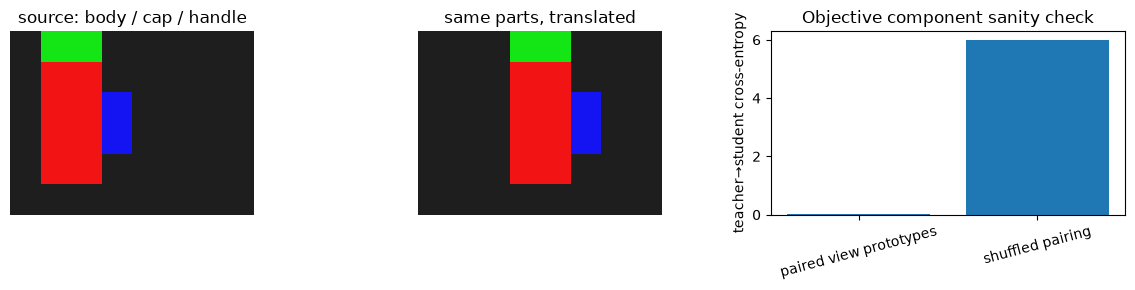

prototype CE: paired 0.034544 shuffled 5.990146


In [4]:
source_image,source_labels = utils.part_image(0)
target_image,target_labels = utils.part_image(2)
source_grid = patch_means(source_image)
target_grid = patch_means(target_image)
source = source_grid.reshape(-1,3)
target = target_grid.reshape(-1,3)
prototype_logits = np.eye(3)*3
paired_loss = teacher_student_loss(prototype_logits,prototype_logits,np.zeros(3),.5,.5)
shuffled_loss = teacher_student_loss(prototype_logits,np.roll(prototype_logits,1,axis=0),np.zeros(3),.5,.5)
fig,axes=plt.subplots(1,3,figsize=(12,3))
axes[0].imshow(source_image);axes[0].set_title("source: body / cap / handle");axes[0].axis("off")
axes[1].imshow(target_image);axes[1].set_title("same parts, translated");axes[1].axis("off")
axes[2].bar(["paired view prototypes","shuffled pairing"],[paired_loss,shuffled_loss]);axes[2].set(ylabel="teacher→student cross-entropy",title="Objective component sanity check");axes[2].tick_params(axis="x",labelrotation=15)
plt.tight_layout();plt.show()
print("prototype CE: paired",round(paired_loss,6),"shuffled",round(shuffled_loss,6))

<details><summary>Help - what did this objective test establish?</summary>

The prototype calculation checks centring, temperature and pairing numerically. Those logits are declared, not produced by a learned teacher or student. DINO learns across crops using a momentum teacher and collapse-avoidance machinery; DINOv2 adds a larger representation-learning recipe including patch-level objectives. A low loss on our declared prototypes is no evidence of self-supervised representation learning.

</details>

## Summary of 1️⃣

We have genuine rendered pixels and an exact grid correspondence. The objective exercise connects the analysis to its source while retaining the training boundary.

# 2️⃣ Visualise and match parts

> ##### Learning Objectives
>
> - Fit one PCA basis and use cosine correspondence with a shuffled-spatial control.

PCA is a view of feature variance. Fit one mean $\mu$ and one orthonormal component matrix $C$ on the source, then apply $\tilde X=(X-\mu)C^T$ to **both** images. Fitting independent PCA bases can rotate or flip the displayed colours and make corresponding parts appear different.

For matching, normalise each feature and choose the target with maximum cosine similarity. A high similarity is not necessarily a unique correspondence: every constant-red patch is equally similar here. We score **part identity**, not exact pixel identity. Mutual nearest neighbours are a stricter consistency check, not a guarantee that every object patch has a unique match.

### Exercise - implement `fit_pca`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the source feature mean and the first `k` right singular vectors as rows. For deterministic display, flip each component so its largest absolute loading is positive. Require `1 <= k <= min(n_examples,width)`.

In [5]:
def fit_pca(features, k=3):
    if k < 1 or k > min(features.shape):
        raise ValueError("Invalid component count")
    mean = features.mean(axis=0)
    _,_,vt = np.linalg.svd(features-mean,full_matrices=False)
    components = vt[:k].copy()
    for row in components:
        if row[np.abs(row).argmax()] < 0:
            row *= -1
    return mean,components


tests.test_fit_pca(fit_pca)

All tests in test_fit_pca passed!


<details>
<summary>Hint</summary>

Do not recompute the target basis. SVD signs are arbitrary; the display sign rule does not change the subspace.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_fit_pca passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `project_pca`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Project using the supplied source mean and components. Keep all example rows. Do not whiten or refit; those would be different representations.

In [6]:
def project_pca(features, mean, components):
    return (features-mean) @ components.T


tests.test_project_pca(project_pca)

All tests in test_project_pca passed!


<details>
<summary>Hint</summary>

Subtract the source mean, even when projecting a target image with another object location.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_project_pca passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `cosine_matches`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return best target indices and cosine scores for each source row. Zero vectors remain zero after an epsilon-safe norm division; ties choose the first target index. Never compare unnormalised dot products here.

In [7]:
def cosine_matches(source, target):
    s = source / np.maximum(np.linalg.norm(source,axis=1,keepdims=True),1e-12)
    t = target / np.maximum(np.linalg.norm(target,axis=1,keepdims=True),1e-12)
    scores = s @ t.T
    indices = scores.argmax(axis=1)
    return indices,scores[np.arange(len(source)),indices]


tests.test_cosine_matches(cosine_matches)

All tests in test_cosine_matches passed!


<details>
<summary>Hint</summary>

A global maximum would give one pair, not one target per source patch.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_cosine_matches passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `mutual_matches`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Given source→target indices and target→source indices, return a boolean source mask whose mapping returns to the same source index. Do not assume the two images have the same number of patches.

In [8]:
def mutual_matches(forward, backward):
    return backward[forward] == np.arange(len(forward))


tests.test_mutual_matches(mutual_matches)

All tests in test_mutual_matches passed!


<details>
<summary>Hint</summary>

Compose the two mappings before comparing with source indices.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_mutual_matches passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `correspondence_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Score the part labels of predicted target matches for the selected source rows. `source_labels`/`target_labels` are flattened; `source_mask` specifies the denominator, normally source foreground. Reject an empty denominator.

In [9]:
def correspondence_accuracy(source_labels, target_labels, matches, source_mask):
    if not np.any(source_mask):
        raise ValueError("No selected source patches")
    return float(np.mean(source_labels[source_mask] == target_labels[matches[source_mask]]))


tests.test_correspondence_accuracy(correspondence_accuracy)

All tests in test_correspondence_accuracy passed!


<details>
<summary>Hint</summary>

Do not let background area dominate a part-correspondence score.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_correspondence_accuracy passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

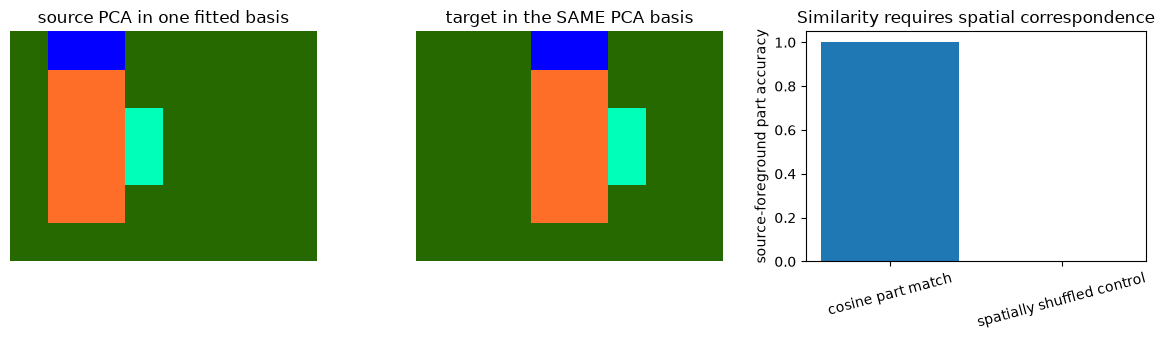

foreground patches 12 mutual foreground matches 3 part accuracy 1.0 shuffled 0.0


In [10]:
mean,components = fit_pca(source)
pca_source = project_pca(source,mean,components)
pca_target = project_pca(target,mean,components)
low,high = pca_source.min(axis=0),pca_source.max(axis=0)
forward,similarities = cosine_matches(source,target)
backward,_ = cosine_matches(target,source)
mutual = mutual_matches(forward,backward)
foreground = source_labels.reshape(-1)>0
shuffle = np.random.default_rng(5).permutation(len(target))
shuffled_forward,_ = cosine_matches(source,target[shuffle])
matched_accuracy = correspondence_accuracy(source_labels.ravel(),target_labels.ravel(),forward,foreground)
shuffled_accuracy = correspondence_accuracy(source_labels.ravel(),target_labels.ravel(),shuffled_forward,foreground)
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
axes[0].imshow(utils.grid_rgb(pca_source,source_labels.shape,low,high));axes[0].set_title("source PCA in one fitted basis");axes[0].axis("off")
axes[1].imshow(utils.grid_rgb(pca_target,target_labels.shape,low,high));axes[1].set_title("target in the SAME PCA basis");axes[1].axis("off")
axes[2].bar(["cosine part match","spatially shuffled control"],[matched_accuracy,shuffled_accuracy]);axes[2].set(ylabel="source-foreground part accuracy",ylim=(0,1.05),title="Similarity requires spatial correspondence");axes[2].tick_params(axis="x",labelrotation=15)
plt.tight_layout();plt.show()
print("foreground patches",foreground.sum(),"mutual foreground matches",(mutual & foreground).sum(),"part accuracy",matched_accuracy,"shuffled",shuffled_accuracy)

<details><summary>Help - why so few mutual matches?</summary>

Constant-colour patches tie. Every red source patch chooses the first red target patch, whose reverse match returns only to the first red source patch. Thus perfect part accuracy can coexist with very few mutual matches. The spatially shuffled control leaves target feature vectors intact but assigns them to wrong locations, while ground-truth labels retain their positions. It specifically tests image-grid alignment; it is not a test that colour similarity disappears.

</details>

## Summary of 2️⃣

A PCA colour map is descriptive, and part-level correspondence is weaker than exact point matching. Both require a recorded spatial mapping.

# 3️⃣ Find the norm artifact

> ##### Learning Objectives
>
> - Measure high-norm tokens, query attention and the limits of interpreting feature visualisations.

Attention depends on dot products, so both direction and norm matter. We inject a large multiple of a grey background vector at patch0. This creates an exact, declared artifact: it can dominate a red query’s attention without becoming a better red **cosine** match.

The register-token paper reports high-norm background tokens used for internal computation in learned ViTs, and studies additional training-time tokens as a remedy. Multiplying a pixel feature here is an analogy for the measurement problem, not a reproduction of how those learned artifacts arise. Normalising keys is a diagnostic intervention; it is **not** the paper’s register-token training method.

### Exercise - implement `norm_outliers`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Mark rows whose L2 norm exceeds `multiplier * median(norms)`. Use a strict comparison. This robust descriptive rule is fixed before inspecting the injected example; it is not a scientific model-selection threshold.

In [11]:
def norm_outliers(features, multiplier=5.0):
    norms = np.linalg.norm(features,axis=1)
    return norms > multiplier * np.median(norms)


tests.test_norm_outliers(norm_outliers)

All tests in test_norm_outliers passed!


<details>
<summary>Hint</summary>

Use vector norms, not the maximum individual coordinate, and keep the example axis.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_norm_outliers passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `attention_weights`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a stable softmax over key dot products with one query, scaled by `sqrt(width)`. The output is a one-dimensional probability distribution.

In [12]:
def attention_weights(query, keys):
    scores = keys @ query / np.sqrt(keys.shape[1])
    scores -= scores.max()
    weights = np.exp(scores)
    return weights / weights.sum()


tests.test_attention_weights(attention_weights)

All tests in test_attention_weights passed!


<details>
<summary>Hint</summary>

The maximum subtraction prevents the deliberately large token from overflowing exponentials.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_attention_weights passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

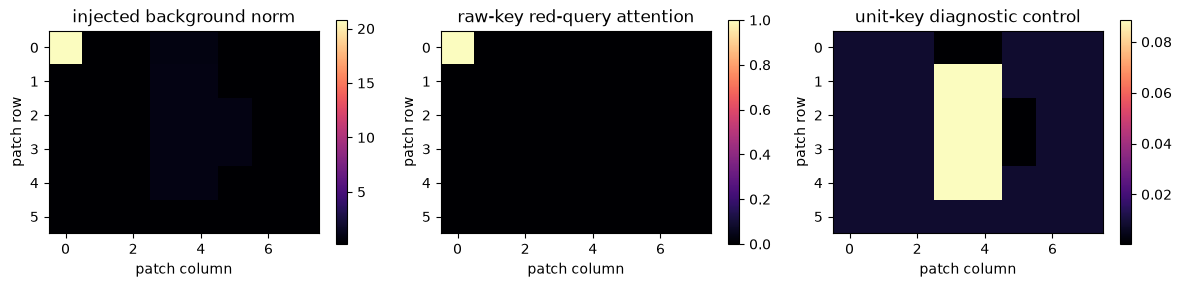

outlier indices [0] raw artifact attention 1.0 unit-key artifact attention 0.008039


In [13]:
artifact = target.copy();artifact[0] *= 100
query = np.array([10.,0,0])
raw_attention = attention_weights(query,artifact)
unit_artifact = artifact/np.maximum(np.linalg.norm(artifact,axis=1,keepdims=True),1e-12)
unit_attention = attention_weights(query,unit_artifact)
outliers = norm_outliers(artifact)
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,values,title in zip(axes,[np.linalg.norm(artifact,axis=1),raw_attention,unit_attention],["injected background norm","raw-key red-query attention","unit-key diagnostic control"]):
    im=ax.imshow(values.reshape(target_labels.shape),cmap="magma");ax.set(title=title,xlabel="patch column",ylabel="patch row");fig.colorbar(im,ax=ax,shrink=.7)
plt.tight_layout();plt.show()
print("outlier indices",np.flatnonzero(outliers).tolist(),"raw artifact attention",round(raw_attention[0],6),"unit-key artifact attention",round(unit_attention[0],6))

<details><summary>Help - what should change under a register intervention?</summary>

The raw attention map can be dominated by the injected background norm. The unit-key control asks whether norm rather than direction explains that dominance. Real register-token evidence requires comparing appropriately trained model variants, with image alignment and downstream task checks; simply appending blank tokens to a pretrained checkpoint is not that experiment.

</details>

## Summary of 3️⃣

A token can attract attention for reasons unrelated to the part the query names. Norm maps and normalised-similarity controls help reveal the distinction.

# 4️⃣ Ask a mask decoder what it reads

> ##### Learning Objectives
>
> - Implement a prompt-conditioned affinity mask and object/background feature replacement controls.

SAM separates a substantial image encoder, prompt encoding and a promptable mask decoder. Our simple decoder instead compares every patch with a positive and a negative prototype. It segments an appearance-defined **part**, not an entire semantic object. This narrow task gives exact masks and transparent interventions, while the bridge explains what a real SAM experiment must retain.

Let each score be cosine(feature,positive) minus cosine(feature,negative). Threshold it at a frozen margin. A positive click inside the red body and a negative click on grey background should select the red body. The target is the red-part mask; scoring against the full three-part object would answer a different question.

### Exercise - implement `masked_pool`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Average feature rows selected by a boolean region mask. Reject an empty selected region. We will use one-click masks and larger regions with the same function.

In [14]:
def masked_pool(features, mask):
    if not np.any(mask):
        raise ValueError("Prompt region is empty")
    return features[mask].mean(axis=0)


tests.test_masked_pool(masked_pool)

All tests in test_masked_pool passed!


<details>
<summary>Hint</summary>

Keep the feature width; do not average all selected scalars into one number.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_masked_pool passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `prompt_mask`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(mask,scores)` from positive-minus-negative cosine affinity and a strict `scores>margin` threshold. Normalise patch rows and both prototypes separately with epsilon-safe denominators.

In [15]:
def prompt_mask(features, positive, negative, margin=0.0):
    f = features/np.maximum(np.linalg.norm(features,axis=1,keepdims=True),1e-12)
    p = positive/max(np.linalg.norm(positive),1e-12)
    n = negative/max(np.linalg.norm(negative),1e-12)
    scores = f @ p - f @ n
    return scores > margin,scores


tests.test_prompt_mask(prompt_mask)

All tests in test_prompt_mask passed!


<details>
<summary>Hint</summary>

A background prototype is evidence to subtract, not another positive target.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_prompt_mask passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `mask_iou`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return intersection divided by union for boolean masks. If both are empty, define IoU1 explicitly. Do not divide by the size of the image or the target alone.

In [16]:
def mask_iou(predicted, target):
    intersection = np.logical_and(predicted,target).sum()
    union = np.logical_or(predicted,target).sum()
    return float(intersection/union) if union else 1.0


tests.test_mask_iou(mask_iou)

All tests in test_mask_iou passed!


<details>
<summary>Hint</summary>

IoU penalises both missed foreground and extra predicted background.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_mask_iou passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

### Exercise - implement `replace_region`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Copy a target feature matrix and replace rows under a boolean region mask with the corresponding clean-donor rows. Shapes and spatial alignment must already agree. Keep both original inputs unchanged.

In [17]:
def replace_region(target, donor, mask):
    out = target.copy()
    out[mask] = donor[mask]
    return out


tests.test_replace_region(replace_region)

All tests in test_replace_region passed!


<details>
<summary>Hint</summary>

This is a matched activation replacement, not masking the input pixels to black.

</details>

<details>
<summary>Expected output</summary>

The immediate independent fixture prints `All tests in test_replace_region passed!`. Check the numerical example in the next experiment before continuing; a passing test checks its stated cases, not a scientific claim.

</details>

Before the signature panel, predict which intervention restores the red-part mask after red-body features are replaced by blue. Use the same number of background patches for the control. Also predict the result of a wrong positive prompt taken from the blue handle. Record confidence before displaying the results.

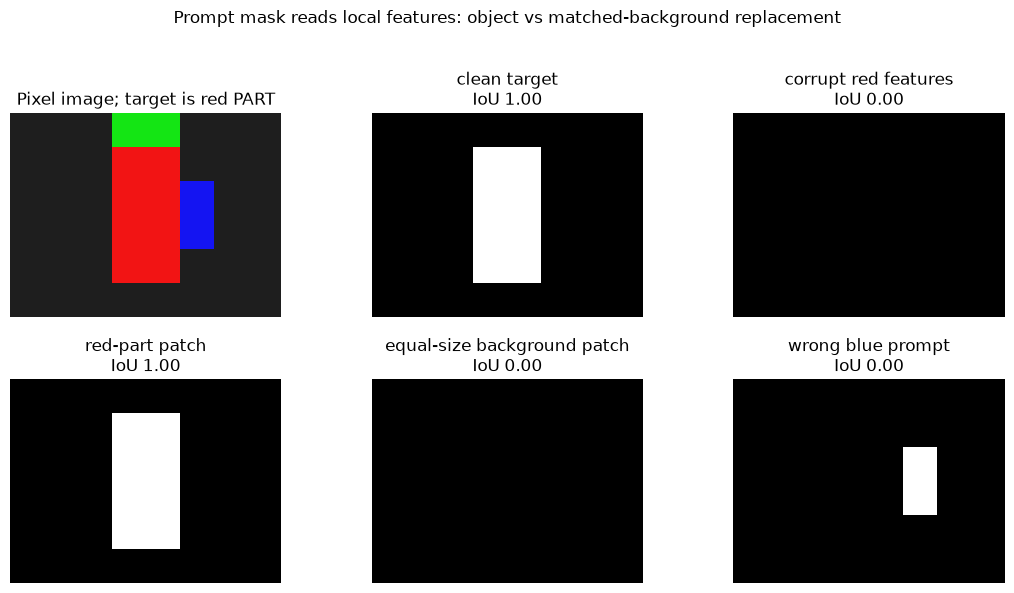

mask IoUs [('clean target', 1.0), ('corrupt red features', 0.0), ('red-part patch', 1.0), ('equal-size background patch', 0.0), ('wrong blue prompt', 0.0)]


In [18]:
truth = target_labels.ravel()==1
positive = masked_pool(target,truth)
negative = masked_pool(target,target_labels.ravel()==0)
wrong_positive = masked_pool(target,target_labels.ravel()==3)
corrupt = target.copy();corrupt[truth] = utils.PALETTE[3]
background = np.zeros(len(target),dtype=bool)
background[np.flatnonzero(target_labels.ravel()==0)[:int(truth.sum())]] = True
object_patched = replace_region(corrupt,target,truth)
bg_patched = replace_region(corrupt,target,background)
conditions={"clean target":target,"corrupt red features":corrupt,"red-part patch":object_patched,"equal-size background patch":bg_patched}
masks={name:prompt_mask(values,positive,negative)[0] for name,values in conditions.items()}
masks["wrong blue prompt"] = prompt_mask(target,wrong_positive,negative)[0]
fig,axes=plt.subplots(2,3,figsize=(11,6))
axes.flat[0].imshow(target_image);axes.flat[0].set_title("Pixel image; target is red PART");axes.flat[0].axis("off")
for ax,(name,mask) in zip(list(axes.flat)[1:],masks.items()):
    ax.imshow(mask.reshape(target_labels.shape),vmin=0,vmax=1,cmap="gray");ax.set_title(f"{name}\nIoU {mask_iou(mask,truth):.2f}");ax.axis("off")
fig.suptitle("Prompt mask reads local features: object vs matched-background replacement")
plt.tight_layout(rect=(0,0,1,.94),h_pad=3.0);plt.show()
print("mask IoUs",[(name,mask_iou(mask,truth)) for name,mask in masks.items()])

## Interpreting the result

The fixed CPU reference gives foreground part accuracy12/12 versus0/12 after spatial shuffling, with only3 mutual foreground matches because of exact part-colour ties. The injected background token gets attention1.000000 with raw keys and0.008039 after the unit-key diagnostic. Clean/red-part-patched mask IoU is1; corrupted, background-patched and wrong-prompt IoU is0. These are the specified teaching-fixture outputs. The mask panel is the signature result. Red-part replacement should restore the declared red mask, while an equally large background replacement cannot repair the corrupted red features. A blue positive prompt selects another part and scores poorly against the red target. The positive/negative prototypes were fixed from the known clean example; they are privileged task annotations, not an automated discovery procedure.

## Bridge to DINO, DINOv2, registers and SAM

For **DINO/DINOv2**, replace mean-RGB patch vectors with a pinned model’s patch outputs while preserving its resize/crop geometry. Inspect the official feature interfaces and keep class/register tokens out of the grid. Fit the PCA basis on a declared collection and freeze it before comparisons; use annotated correspondences and shuffled-grid controls, not attractive colours alone. DINOv2 is a larger learned-feature recipe, not this teacher-loss function plus a few steps.

For **registers**, inspect norm distributions and downstream maps in the trained variants studied by the paper. This notebook’s injected large background vector and unit-key diagnostic isolate a norm effect; they do not demonstrate the benefit of training with registers.

For **SAM**, keep the model’s image resize/padding coordinates, prompt coordinates, positional image embeddings, prompt encoder, mask decoder and output upsampling path. Cache the actual encoder embedding, replace aligned regions, and rerun the same prompt decoder with the same point/box prompts. Score real masks with background and wrong-prompt controls. Our affinity mask has none of SAM’s learned decoder architecture or ambiguity handling; it makes the intervention logic inspectable before native qualification.

## Try it yourself

Change the target from the red body to the entire three-part object, leaving the decoder and prompt fixed. Predict IoU before running. Should a perfect colour-part mask pass an object-segmentation test? This changes the target definition rather than only the random seed.

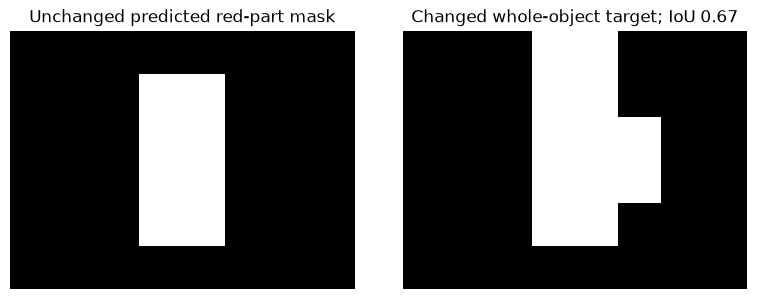

In [19]:
whole_object = target_labels.ravel()>0
part_mask = masks["clean target"]
whole_iou = mask_iou(part_mask,whole_object)
fig,axes=plt.subplots(1,2,figsize=(8,3));axes[0].imshow(part_mask.reshape(target_labels.shape),cmap="gray");axes[0].set_title("Unchanged predicted red-part mask");axes[1].imshow(whole_object.reshape(target_labels.shape),cmap="gray");axes[1].set_title(f"Changed whole-object target; IoU {whole_iou:.2f}")
for ax in axes:ax.axis("off")
plt.tight_layout();plt.show()

## Limitations

RGB means give appearance correspondence, not learned DINO features or semantic object understanding. Constant part colours make exact point matching ambiguous. The PCA task has three input coordinates, so its three-component view loses no information; this is a basis/geometry exercise, not dimensionality-reduction evidence. The norm artifact is injected. The teacher/student objective omits networks, optimisation, momentum updates, crops and DINOv2’s complete objectives. The prompt decoder is a cosine affinity rule, not SAM. Native pretrained-model patch features, learned register comparisons, mask-decoder patching and natural-image results remain pending.

# ☆ Bonus

Before changing the recipe, write one prediction about the sign and size of a control difference. After running it, explain a mismatch.

## Further reading

- [Caron et al., Emerging Properties in Self-Supervised Vision Transformers (DINO)](https://arxiv.org/abs/2104.14294): read the teacher/student crop objective and emergent visual properties; compare the missing training machinery with our numerical objective component.
- [Oquab et al., DINOv2](https://arxiv.org/abs/2304.07193) and [official DINOv2 code](https://github.com/facebookresearch/dinov2): inspect patch versus class/register feature interfaces and the learned dense-feature examples.
- [Darcet et al., Vision Transformers Need Registers](https://arxiv.org/abs/2309.16588): distinguish observed high-norm background tokens and training-time register tokens from our injected artifact and key-normalisation diagnostic.
- [Kirillov et al., Segment Anything](https://arxiv.org/abs/2304.02643) and [official SAM code](https://github.com/facebookresearch/segment-anything): inspect the image/prompt/mask-decoder split, coordinate transforms and ambiguity outputs before designing real interventions.